In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import os
%matplotlib inline

In [2]:
df = pd.read_csv('dataset.csv')

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0.0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0.0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1.0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1.0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0.0,0.0


In [4]:
df.shape

(341829, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 341829 entries, 0 to 341828
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            341829 non-null  int64  
 1   type            341829 non-null  object 
 2   amount          341829 non-null  float64
 3   nameOrig        341829 non-null  object 
 4   oldbalanceOrg   341829 non-null  float64
 5   newbalanceOrig  341829 non-null  float64
 6   nameDest        341828 non-null  object 
 7   oldbalanceDest  341828 non-null  float64
 8   newbalanceDest  341828 non-null  float64
 9   isFraud         341828 non-null  float64
 10  isFlaggedFraud  341828 non-null  float64
dtypes: float64(7), int64(1), object(3)
memory usage: 28.7+ MB


In [6]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [7]:
from sklearn.model_selection import train_test_split
X = df.drop('isFraud', axis = 1)
y = df['isFraud']

In [8]:
df['isFraud'].value_counts()

,count
isFraud,
0.0,341635
1.0,193


In [9]:
df.drop(['nameOrig', 'nameDest', 'isFlaggedFraud'],axis = 1, inplace = True)

In [10]:
df

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
0,1,PAYMENT,9839.64,170136.00,160296.36,0.00,0.00,0.0
1,1,PAYMENT,1864.28,21249.00,19384.72,0.00,0.00,0.0
2,1,TRANSFER,181.00,181.00,0.00,0.00,0.00,1.0
3,1,CASH_OUT,181.00,181.00,0.00,21182.00,0.00,1.0
4,1,PAYMENT,11668.14,41554.00,29885.86,0.00,0.00,0.0
...,...,...,...,...,...,...,...,...
341824,16,PAYMENT,3463.03,137107.00,133643.97,0.00,0.00,0.0
341825,16,PAYMENT,98.96,93488.00,93389.04,0.00,0.00,0.0
341826,16,CASH_IN,278319.05,93389.04,371708.09,2184489.63,1906170.58,0.0
341827,16,CASH_IN,323648.70,371708.09,695356.79,346310.91,22662.22,0.0


<Axes: xlabel='type', ylabel='count'>

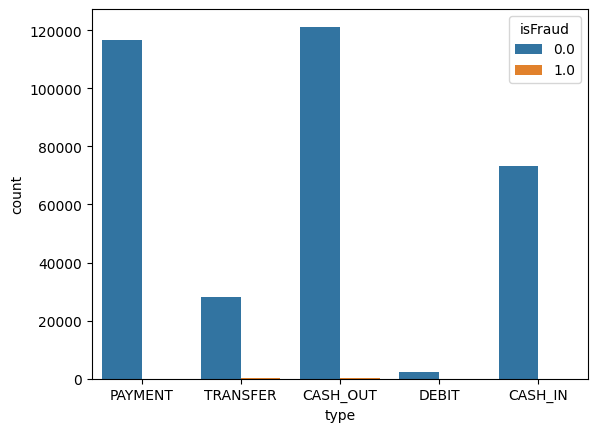

In [11]:
sns.countplot(x = 'type', data = df, hue = 'isFraud')

In [12]:
df.groupby('type')['isFraud'].value_counts()

type      isFraud
CASH_IN   0.0         73082
CASH_OUT  0.0        121207
          1.0            99
DEBIT     0.0          2473
PAYMENT   0.0        116665
TRANSFER  0.0         28208
          1.0            94
Name: count, dtype: int64

In [13]:
df.corr(numeric_only=True)

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
step,1.000000,0.001114,0.003300,0.004003,0.027098,0.003278,-0.026385
amount,0.001114,1.000000,-0.016852,-0.019270,0.214946,0.326079,0.047761
oldbalanceOrg,0.003300,-0.016852,1.000000,0.999119,0.093715,0.063378,-0.001155
newbalanceOrig,0.004003,-0.019270,0.999119,1.000000,0.095262,0.062672,-0.007230
oldbalanceDest,0.027098,0.214946,0.093715,0.095262,1.000000,0.962950,-0.006684
newbalanceDest,0.003278,0.326079,0.063378,0.062672,0.962950,1.000000,-0.003399
isFraud,-0.026385,0.047761,-0.001155,-0.007230,-0.006684,-0.003399,1.000000


<Axes: >

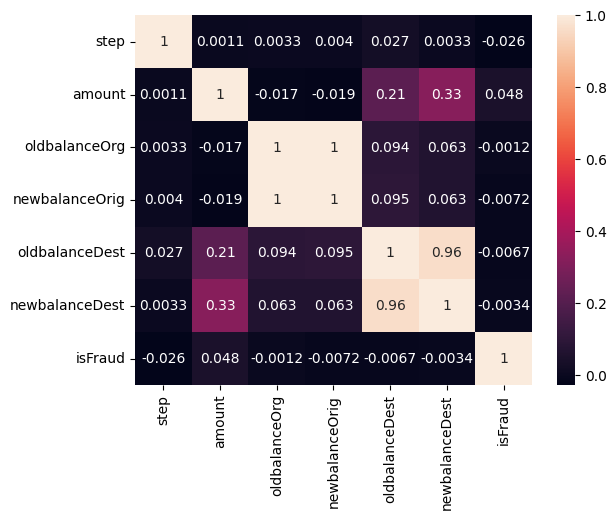

In [14]:
sns.heatmap(df.corr(numeric_only=True), annot = True)

<Axes: xlabel='isFraud', ylabel='amount'>

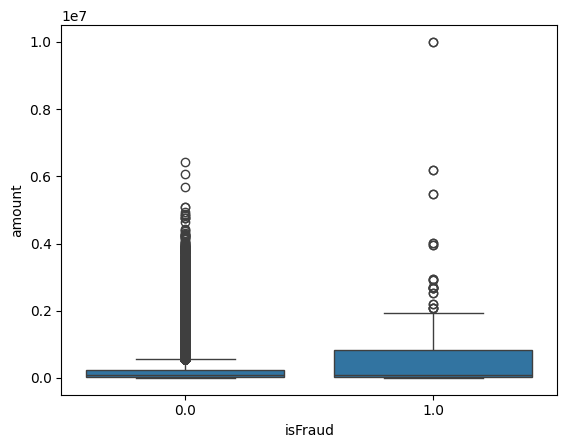

In [15]:
sns.boxplot(x = 'isFraud', y = 'amount', data = df)

In [16]:
df['balanceOrg'] = (
    df['oldbalanceOrg'] - df['newbalanceOrig']
)
df['balanceDest'] = (
    df['newbalanceDest'] - df['oldbalanceDest']
)

In [17]:
df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceOrg,balanceDest
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0.0,9839.64,0.0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0.0,1864.28,0.0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1.0,181.00,0.0
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1.0,181.00,-21182.0
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0.0,11668.14,0.0


<Axes: >

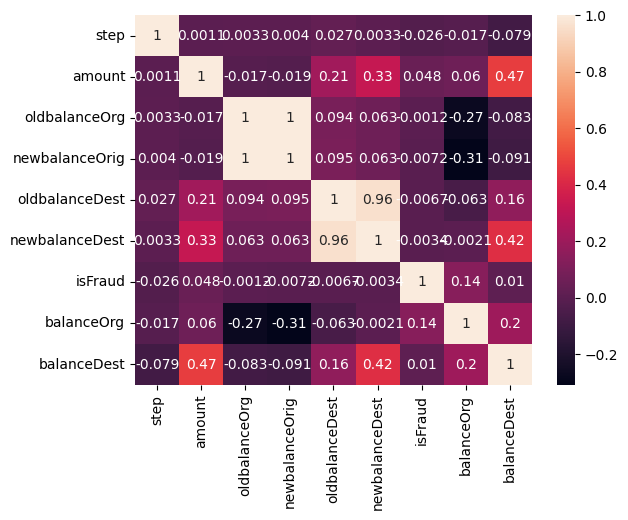

In [18]:
sns.heatmap(df.corr(numeric_only=True), annot = True)

In [19]:
df.isnull().sum()

,0
step,0
type,0
amount,0
oldbalanceOrg,0
newbalanceOrig,0
oldbalanceDest,1
newbalanceDest,1
isFraud,1
balanceOrg,0
balanceDest,1


In [20]:
df.dropna(inplace = True)

In [21]:
df.isnull().sum()

,0
step,0
type,0
amount,0
oldbalanceOrg,0
newbalanceOrig,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0
balanceOrg,0
balanceDest,0


In [22]:
df.drop_duplicates(inplace=True)

In [23]:
df.duplicated().sum()

np.int64(0)

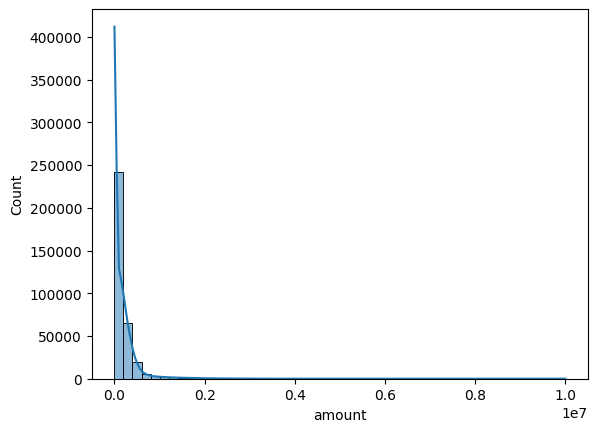

In [24]:
sns.histplot(df['amount'], bins=50, kde=True)
plt.show()

In [25]:
X

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.00,0.00,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.00,0.00,0.0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,0.0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.00,0.00,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.00,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...
341824,16,PAYMENT,3463.03,C1446181326,137107.00,133643.97,M1467424582,0.00,0.00,0.0
341825,16,PAYMENT,98.96,C752066037,93488.00,93389.04,M1119815976,0.00,0.00,0.0
341826,16,CASH_IN,278319.05,C50488376,93389.04,371708.09,C1331875424,2184489.63,1906170.58,0.0
341827,16,CASH_IN,323648.70,C1826674225,371708.09,695356.79,C114649116,346310.91,22662.22,0.0


In [26]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

In [27]:
df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceOrg,balanceDest
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0.0,9839.64,0.0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0.0,1864.28,0.0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1.0,181.00,0.0
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1.0,181.00,-21182.0
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0.0,11668.14,0.0


In [28]:
from sklearn.model_selection import train_test_split

# Redefine X and y using the cleaned and preprocessed df
X = df.drop('isFraud', axis=1)
y = df['isFraud']

# Perform the train-test split on the cleaned data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [29]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Redefine numerical and categorical columns excluding the target column 'isFraud'
numerical_columns = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = X_train.select_dtypes(include=['object']).columns

scaler = StandardScaler()
encoder = OneHotEncoder(drop='first')

preprocessor = ColumnTransformer(
    transformers=[
        ('num', scaler, numerical_columns),
        ('cat', encoder, categorical_columns)
    ])

X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

In [30]:
df['isFraud'].value_counts()

,count
isFraud,
0.0,341604
1.0,193


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced'
)
lr_model.fit(X_train_preprocessed, y_train)

y_pred_lr = lr_model.predict(X_test_preprocessed)

accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression Accuracy: {accuracy_lr}")
print(classification_report(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.9096108835576361
              precision    recall  f1-score   support

         0.0       1.00      0.91      0.95     68321
         1.0       0.01      0.90      0.01        39

    accuracy                           0.91     68360
   macro avg       0.50      0.90      0.48     68360
weighted avg       1.00      0.91      0.95     68360

[[62146  6175]
 [    4    35]]


In [32]:
df.shape

(341797, 10)

In [33]:
# Get fraud probabilities
y_prob = lr_model.predict_proba(X_test_preprocessed)[:, 1]

# Try a higher threshold
threshold = 0.7

# Generate predictions
y_pred_new = (y_prob >= threshold).astype(int)

print(classification_report(y_test, y_pred_new))
print(confusion_matrix(y_test, y_pred_new))

              precision    recall  f1-score   support

         0.0       1.00      0.97      0.98     68321
         1.0       0.01      0.74      0.02        39

    accuracy                           0.97     68360
   macro avg       0.51      0.85      0.50     68360
weighted avg       1.00      0.97      0.98     68360

[[65990  2331]
 [   10    29]]


In [34]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=42,class_weight='balanced')
dt_model.fit(X_train_preprocessed, y_train)

y_pred_dt = dt_model.predict(X_test_preprocessed)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {accuracy_dt}")
print(classification_report(y_test, y_pred_dt))
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9996342890579286
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     68321
         1.0       0.75      0.54      0.63        39

    accuracy                           1.00     68360
   macro avg       0.87      0.77      0.81     68360
weighted avg       1.00      1.00      1.00     68360

[[68314     7]
 [   18    21]]


In [35]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42,class_weight='balanced')
rf_model.fit(X_train_preprocessed, y_train)

y_pred_rf = rf_model.predict(X_test_preprocessed)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy_rf}")
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Accuracy: 0.9996635459332943
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     68321
         1.0       0.90      0.46      0.61        39

    accuracy                           1.00     68360
   macro avg       0.95      0.73      0.81     68360
weighted avg       1.00      1.00      1.00     68360

[[68319     2]
 [   21    18]]


In [37]:
!pip install xgboost

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xgb_model = XGBClassifier(random_state=42, class_weight='balanced')
xgb_model.fit(X_train_preprocessed, y_train)

y_pred_xgb = xgb_model.predict(X_test_preprocessed)

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
print(f"XGBoost Accuracy: {accuracy_xgb}")
print(classification_report(y_test, y_pred_xgb))
print(confusion_matrix(y_test, y_pred_xgb))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 68.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.6/206.6 MB 21.7 MB/s  0:00:09
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]
XGBoost Accuracy: 0.9997513165593914
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     68321
         1.0       0.92      0.62      0.74        39

    accuracy                           1.00     68360
   macro avg       0.96      0.81      0.87     68360
weighted avg       1.00      1.00      1.00     68360

[[68319     2]
 [   15    24]]


In [38]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train_preprocessed, y_train)

y_pred_gb = gb_model.predict(X_test_preprocessed)

accuracy_gb = accuracy_score(y_test, y_pred_gb)
print(f"Gradient Boosting Accuracy: {accuracy_gb}")
print(classification_report(y_test, y_pred_gb))
print(confusion_matrix(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.9996342890579286
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     68321
         1.0       0.85      0.44      0.58        39

    accuracy                           1.00     68360
   macro avg       0.92      0.72      0.79     68360
weighted avg       1.00      1.00      1.00     68360

[[68318     3]
 [   22    17]]


In [39]:
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# 1. Initialize the base XGBoost classifier
xgb_model = xgb.XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    class_weight='balanced'
)

# 2. Define the parameter grid to search
# Total combinations here = 3 (depth) * 3 (lr) * 2 (estimators) * 2 (subsample) = 36 models * 3 folds = 108 fits
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [100, 300],
    'subsample': [0.8, 1.0]
}

# 3. Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='roc_auc',  # Use 'f1', 'precision', or 'roc_auc' depending on your goal
    cv=3,               # 3-fold cross-validation
    n_jobs=-1,          # Use all available CPU cores
    verbose=1           # Print progress updates
)

# 4. Fit the grid search to the training data
grid_search.fit(X_train_preprocessed, y_train)

# 5. Extract results
print("Best Parameters Found:")
print(grid_search.best_params_)
print(f"Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")

# 6. Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test_preprocessed)
print("\nTest Set Classification Report:")
print(classification_report(y_test, y_pred))

Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters Found:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}
Best Cross-Validation ROC-AUC: 0.9910

Test Set Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     68321
         1.0       0.91      0.54      0.68        39

    accuracy                           1.00     68360
   macro avg       0.96      0.77      0.84     68360
weighted avg       1.00      1.00      1.00     68360



In [40]:
print(confusion_matrix(y_test, y_pred))

[[68319     2]
 [   18    21]]


In [41]:
import pickle

In [42]:
pickle.dump(xgb_model, open('xgb_model.pkl', 'wb'))
